# CS781 Phase 1 — Notebook 3: Train a language model → evaluate → submission

**This version trains Architecture A0: a vanilla GPT-2-style decoder-only Transformer** (our own implementation,
our own 32k tokenizer, trained from scratch). Later architectures replace only the *Model* cell.

| Step | What happens |
|---|---|
| 1 | config: everything about the run in one dict (saved with the run) |
| 2 | locate NB1/NB2 outputs, build the Supreme-Court local eval set |
| 3 | data: random 1025-token windows from memory-mapped shards, mixed across sources by weight |
| 4 | model: GPT-2-style decoder (learned positions, LayerNorm, GELU MLP, multi-head attention) |
| 5 | generation: left padding, KV-cache, word-count stopping, decoding options |
| 6 | training: fp16, AdamW, warmup+cosine, both T4 GPUs (DDP), checkpoints, clean stop before 12 h |
| 7 | curves + val loss per source |
| 8 | decoding sweep on the local set with the official metric → pick best → `submission.zip` |

**Kaggle settings**: Accelerator **GPU T4 x2**, Internet ON, secret `HF`.
**Inputs**: output of NB1 (tokenizer, eval) and NB2 (shards). **To resume** an interrupted run: also attach the previous
version of *this* notebook (same `RUN_NAME`) and commit again — training continues from the last checkpoint.

⚠️ Do not run any cell that uses the GPU *before* the training cell (two GPUs are used by forking two worker processes,
which requires CUDA to be untouched in the main process). The cells are ordered so this is automatic.

In [1]:
!pip -q install tokenizers bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.8 MB/s eta 0:00:00


In [2]:
# ============================================================================================
# SHARED SETUP  —  paste this SAME cell at the top of every Phase-1 notebook.
# Works on Kaggle (Save & Commit or interactive), Colab (Drive) and local machines.
# ============================================================================================
import os, sys, json, time, glob, shutil, random, math, re, zlib, hashlib, gc
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np

os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")

SESSION_START = time.time()
TIME_BUDGET_H = 11.0   # Kaggle kills a session at 12h and then saves NOTHING -> every long loop stops itself before this

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/working")
PROJECT   = "cs781_p1"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT, SCRATCH = Path("/content/drive/MyDrive") / PROJECT, Path("/content/scratch")   # Drive = persistent
elif IN_KAGGLE:
    ROOT, SCRATCH = Path("/kaggle/working") / PROJECT, Path("/tmp/cs781_scratch")       # working = saved on commit
else:
    ROOT, SCRATCH = Path("./") / PROJECT, Path("./scratch")
ROOT    = Path(os.environ.get("CS781_ROOT", ROOT))
SCRATCH = Path(os.environ.get("CS781_SCRATCH", SCRATCH))
ROOT.mkdir(parents=True, exist_ok=True); SCRATCH.mkdir(parents=True, exist_ok=True)

ENV = "colab" if IN_COLAB else "kaggle" if IN_KAGGLE else "local"
print(f"env={ENV}  ROOT={ROOT}  SCRATCH={SCRATCH}")
for p in {ROOT, SCRATCH}:
    du = shutil.disk_usage(p); print(f"  disk @ {p}: free {du.free/1e9:.1f} GB / total {du.total/1e9:.1f} GB")


# ---------------------------------------------------------------- small utilities
def time_left_h():
    return TIME_BUDGET_H - (time.time() - SESSION_START) / 3600

def save_json(obj, path):
    """Atomic write: a crash mid-write can never leave a half-written (corrupt) state file."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=1)
    os.replace(tmp, path)

def load_json(path, default=None):
    path = Path(path)
    if not path.exists(): return default
    with open(path, encoding="utf-8") as f: return json.load(f)

def restore_from_kaggle_inputs(subdirs):
    """Kaggle 'Save & Commit' starts every run with an EMPTY /kaggle/working.
    To resume, attach the output of the previous version (Add Input -> Your Work -> Notebook output).
    This copies <PROJECT>/<subdir> from any attached input into ROOT (never overwriting newer local files)."""
    if not IN_KAGGLE: return
    for sub in subdirs:
        for cand in sorted(glob.glob(f"/kaggle/input/**/{PROJECT}/{sub}", recursive=True)):
            n = 0
            for src in Path(cand).rglob("*"):
                if src.is_file():
                    dst = ROOT / sub / src.relative_to(cand)
                    if not dst.exists():
                        dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(src, dst); n += 1
            print(f"restored {n} files: {cand} -> {ROOT/sub}")

def find_artifact(rel):
    """Look for ROOT/rel first, then inside any attached Kaggle input."""
    p = ROOT / rel
    if p.exists(): return p
    if IN_KAGGLE:
        hits = sorted(glob.glob(f"/kaggle/input/**/{PROJECT}/{rel}", recursive=True))
        if hits: return Path(hits[0])
    return None

def get_hf_token():
    if os.environ.get("HF_TOKEN"): return os.environ["HF_TOKEN"]
    try:
        if IN_KAGGLE:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret("HF")
        if IN_COLAB:
            from google.colab import userdata
            return userdata.get("HF")
    except Exception as e:
        print("Could not read secret 'HF':", e)
    return None

HF_TOKEN = get_hf_token()
if HF_TOKEN: os.environ["HF_TOKEN"] = HF_TOKEN
print("HF token found:", bool(HF_TOKEN))

# Optional: a PRIVATE HF dataset repo used only to move YOUR OWN artifacts between accounts/sessions.
HF_ARTIFACT_REPO = None   # e.g. "your-hf-username/cs781-p1-artifacts"

def hf_push(subdir):
    if not HF_ARTIFACT_REPO: print("HF_ARTIFACT_REPO not set; skip push"); return
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    api.create_repo(HF_ARTIFACT_REPO, repo_type="dataset", private=True, exist_ok=True)
    api.upload_folder(folder_path=str(ROOT / subdir), path_in_repo=subdir,
                      repo_id=HF_ARTIFACT_REPO, repo_type="dataset")
    print("pushed", subdir)

def hf_pull(subdir):
    if not HF_ARTIFACT_REPO: return
    from huggingface_hub import snapshot_download
    snapshot_download(HF_ARTIFACT_REPO, repo_type="dataset", allow_patterns=[f"{subdir}/*", f"{subdir}/**"],
                      local_dir=str(ROOT), token=HF_TOKEN)
    print("pulled", subdir)


# ---------------------------------------------------------------- data utilities
# These MUST be identical in every notebook (the train/val split and cleaning depend on them).
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
SOURCE_NAMES = ["acts", "high_courts", "supreme_court", "tribunals"]   # processing order (matters for dedup)
VAL_PER_10K  = 100            # 1% of documents of every source are held out (document-level split)
PROMPT_WORDS, CONT_WORDS = 512, 128

def extract_text(rec):
    if rec is None: return ""
    if isinstance(rec, str): return rec
    if isinstance(rec, list): return "\n".join(extract_text(r) for r in rec)
    if isinstance(rec, dict):
        for k in ("text", "content", "document", "judgment", "judgement", "body"):
            if k in rec: return extract_text(rec[k])
    return ""

def iter_docs(path):
    """Stream documents from a (possibly multi-GB) JSON file WITHOUT loading it all into RAM.
    Handles: [ {...}, ... ]   |   { id: {...}, ... }   |   JSON-lines."""
    import ijson
    with open(path, "rb") as f:
        head = f.read(1 << 16).lstrip()
        f.seek(0)
        if head[:1] == b"[":
            for rec in ijson.items(f, "item", use_float=True):
                yield extract_text(rec)
            return
        first_line = f.readline(50_000_000); second = f.read(1 << 10).lstrip()[:1]
        f.seek(0)
        is_jsonl = False
        if first_line.endswith(b"\n") and second == b"{":
            try: json.loads(first_line); is_jsonl = True
            except Exception: pass
        if is_jsonl:
            for line in f:
                if line.strip(): yield extract_text(json.loads(line))
        else:
            for _, rec in ijson.kvitems(f, "", use_float=True):
                yield extract_text(rec)

_ZW = re.compile(r"[​‌‍﻿­]")
_WS_ALL = re.compile(r"\s+")
_HSPACE = re.compile(r"[^\S\n]+")
_MANY_NL = re.compile(r"\n\s*\n\s*\n+")

def normalize(text, mode):
    """'collapse_all'  -> every whitespace run becomes one space (text looks like ' '.join(text.split()))
       'keep_newlines' -> collapse spaces/tabs, keep at most one blank line"""
    text = _ZW.sub("", text)
    if mode == "collapse_all":
        return _WS_ALL.sub(" ", text).strip()
    text = _HSPACE.sub(" ", text.replace("\r\n", "\n").replace("\r", "\n"))
    text = "\n".join(l.strip() for l in text.split("\n"))
    return _MANY_NL.sub("\n\n", text).strip()

def hash64(text):
    return int.from_bytes(hashlib.blake2b(text.encode("utf-8", "ignore"), digest_size=8).digest(), "little")

def doc_split(source, idx):
    return "val" if zlib.crc32(f"{source}:{idx}".encode()) % 10000 < VAL_PER_10K else "train"

def list_phase1_files(local_raw_dir=None):
    """Return {'train': {source: repo_path}, 'test': repo_path, 'sizes': {repo_path: bytes}}."""
    if local_raw_dir:
        files = [str(Path(p).relative_to(local_raw_dir)) for p in glob.glob(f"{local_raw_dir}/**/*.json*", recursive=True)]
        sizes = {f: os.path.getsize(Path(local_raw_dir) / f) for f in files}
    else:
        from huggingface_hub import HfApi
        api = HfApi(token=HF_TOKEN)
        try:
            entries = list(api.list_repo_tree(HF_DATASET_REPO, repo_type="dataset",
                                              path_in_repo="Phase_1_Pretraining", recursive=True))
            files = [e.path for e in entries if getattr(e, "size", None) is not None]
            sizes = {e.path: e.size for e in entries if getattr(e, "size", None) is not None}
        except Exception as e:
            print("list_repo_tree failed (", e, ") -> falling back to list_repo_files")
            files = [f for f in api.list_repo_files(HF_DATASET_REPO, repo_type="dataset") if f.startswith("Phase_1")]
            sizes = {}
    out = {"train": {}, "test": None, "sizes": sizes}
    for f in files:
        name = Path(f).name.lower()
        if not name.endswith((".json", ".jsonl")): continue
        if "test" in name: out["test"] = f
        for s in SOURCE_NAMES:
            if name.startswith("train") and s in name: out["train"][s] = f
    return out

def get_raw_file(repo_path, local_raw_dir=None):
    if local_raw_dir:
        return Path(local_raw_dir) / repo_path
    from huggingface_hub import hf_hub_download
    return Path(hf_hub_download(HF_DATASET_REPO, repo_path, repo_type="dataset", token=HF_TOKEN,
                                local_dir=str(SCRATCH / "raw")))

def drop_raw_file(path, local_raw_dir=None):
    if local_raw_dir: return          # never delete user-provided files
    try: os.remove(path); print("deleted raw", path)
    except OSError: pass

env=kaggle  ROOT=/kaggle/working/cs781_p1  SCRATCH=/tmp/cs781_scratch
  disk @ /kaggle/working/cs781_p1: free 20.9 GB / total 21.0 GB
  disk @ /tmp/cs781_scratch: free 1201.7 GB / total 8758.4 GB
HF token found: True


## 1. Configuration
One dictionary = one experiment. Change values here, give the run a new `RUN_NAME`, commit.

In [3]:
import torch, torch.nn as nn, torch.nn.functional as F, subprocess, csv, datetime, contextlib

SMOKE_TEST = False
SMOKE_TEST = SMOKE_TEST or os.environ.get("CS781_SMOKE") == "1"   # True = tiny model + few steps to test the whole pipeline in ~10 min (not a submission)

CFG = dict(
    run_name      = "A0_gpt2_110M_mix50_300M",
    arch          = "gpt2",             # model family implemented in the Model cell
    tokenizer     = "bpe32768",
    # ---- model (≈110M params) ----
    n_layer = 12, n_head = 12, d_model = 768, ctx_len = 1024, dropout = 0.0,
    # ---- data mix (fractions of training windows drawn from each source) ----
    mix = {"supreme_court": 0.5, "tribunals": 0.2, "high_courts": 0.2, "acts": 0.1},
    # ---- optimisation ----
    token_budget        = 300_000_000,   # total training tokens
    global_batch_tokens = 131_072,       # tokens per optimizer step (= 128 sequences of 1024)
    micro_batch         = 8,             # sequences per GPU per forward pass
    lr = 6e-4, min_lr_frac = 0.1, warmup_frac = 0.02, schedule = "cosine",   # or "wsd"
    wsd_decay_frac = 0.2, weight_decay = 0.1, beta1 = 0.9, beta2 = 0.95, grad_clip = 1.0,
    seed = 1234,
    # ---- monitoring ----
    log_every = 20, eval_every = 250, gen_eval_every = 1000, val_windows = {"supreme_court": 96, "default": 32},
    ckpt_every_min = 30, snapshot_fracs = [0.25, 0.5, 0.75],
    # ---- generation ----
    max_new_tokens = 256, gen_batch = 48,
)
if SMOKE_TEST:
    CFG.update(run_name="SMOKE_" + CFG["run_name"], n_layer=2, n_head=4, d_model=128, token_budget=2_000_000,
               global_batch_tokens=16_384, micro_batch=4, eval_every=40, gen_eval_every=80, log_every=10,
               val_windows={"supreme_court": 8, "default": 4}, gen_batch=32)

# decoding strategies compared on the local set at the end; the best one (by BERTScore) makes the submission
DECODE_SWEEP = {
    "greedy":             dict(temperature=0.0),
    "greedy_nr4":         dict(temperature=0.0, no_repeat_ngram=4),
    "greedy_rp1.15_nr4":  dict(temperature=0.0, rep_penalty=1.15, no_repeat_ngram=4),
    "t0.7_p0.9_nr4":      dict(temperature=0.7, top_p=0.9, no_repeat_ngram=4),
}
EVAL_SET      = "sc_random"     # main local eval set (Supreme Court, random-position windows, 400 examples)
N_EVAL_SWEEP  = 400 if not SMOKE_TEST else 40
TRAIN_RESERVE_H = 1.0           # hours kept free at the end for evaluation + test generation

RUN_DIR = ROOT / "runs" / CFG["run_name"]
RUN_DIR.mkdir(parents=True, exist_ok=True)

# GPUs are counted with nvidia-smi so that CUDA is NOT initialised in this (parent) process.
try:
    NUM_GPUS = len([l for l in subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.splitlines() if l.startswith("GPU")])
except FileNotFoundError:
    NUM_GPUS = 0
NUM_GPUS = int(os.environ.get("CS781_NUM_GPUS", NUM_GPUS))
# NUM_GPUS = 1      # <- uncomment to force a single GPU (e.g. if the 2-GPU launch misbehaves)
print("GPUs:", NUM_GPUS, "| run dir:", RUN_DIR)

GPUs: 2 | run dir: /kaggle/working/cs781_p1/runs/A0_gpt2_110M_mix50_300M


## 2. Inputs: tokenizer, shards, evaluation sets
The **Supreme Court eval set** (`sc_random`): NB1 showed the official test prompts are Supreme Court text
(JSD 0.03 vs ≥0.15 for other sources) starting at random positions, so our main local set is 400 random-position
windows from *held-out* Supreme Court documents.

In [4]:
restore_from_kaggle_inputs(["eval", f"runs/{CFG['run_name']}"])
hf_pull("tokenizer"); hf_pull(f"shards/{CFG['tokenizer']}"); hf_pull("eval")

TOK_PATH  = find_artifact(f"tokenizer/{CFG['tokenizer']}/tokenizer.json")
SUMMARY_P = find_artifact(f"shards/{CFG['tokenizer']}/summary.json")
assert TOK_PATH and SUMMARY_P, "attach NB1 and NB2 outputs"
SHARD_DIR = SUMMARY_P.parent
SHARD_SUMMARY = load_json(SUMMARY_P)
DECISIONS = load_json(find_artifact("data/decisions.json"))
FERTILITY = {k.replace("fertility_", ""): v for k, v in
             {r["name"]: r for r in load_json(find_artifact("tokenizer/tokenizer_report.json"))}[CFG["tokenizer"]].items()
             if k.startswith("fertility_")}
print("shards:", SHARD_DIR, "| complete:", SHARD_SUMMARY["complete"])
for k, v in sorted(SHARD_SUMMARY["totals"].items()):
    print(f"  {k:24s} {v/1e6:9.1f}M tokens")

def build_sc_eval():
    if (ROOT / "eval" / "sc_random_prompts.json").exists(): return
    cands = load_json(find_artifact("eval/candidates_supreme_court.json"))
    prompts = {f"sc_{c['doc_idx']}": {"text": c["rand_prompt"]} for c in cands}
    truth   = {f"sc_{c['doc_idx']}": {"text": c["rand_ref"]} for c in cands}
    save_json(prompts, ROOT / "eval" / "sc_random_prompts.json"); save_json(truth, ROOT / "eval" / "sc_random_truth.json")
build_sc_eval()
for name in ["random_prompts", "random_truth", "baselines"]:
    p = find_artifact(f"eval/{name}.json")
    if p and not (ROOT / "eval" / f"{name}.json").exists(): shutil.copy2(p, ROOT / "eval" / f"{name}.json")
EVAL_PROMPTS = load_json(ROOT / "eval" / f"{EVAL_SET}_prompts.json")
EVAL_TRUTH   = load_json(ROOT / "eval" / f"{EVAL_SET}_truth.json")
print(f"eval set {EVAL_SET}: {len(EVAL_PROMPTS)} examples")

restored 11 files: /kaggle/input/notebooks/aaravoswal/01-data-tokenizer-evalset/cs781_p1/eval -> /kaggle/working/cs781_p1/eval
shards: /kaggle/input/notebooks/aaravoswal/02-encode-shards/cs781_p1/shards/bpe32768 | complete: True
  acts/train                   148.8M tokens
  acts/val                       1.1M tokens
  high_courts/train           1577.4M tokens
  high_courts/val               16.0M tokens
  supreme_court/train          253.2M tokens
  supreme_court/val              2.7M tokens
  tribunals/train             1426.8M tokens
  tribunals/val                 14.0M tokens
eval set sc_random: 400 examples


## 3. Data: random windows from memory-mapped shards
Each training sequence: pick a **source** with probability = mix weight → pick a shard (∝ its size) → random offset →
read 1025 tokens (input = first 1024, target = last 1024, i.e. shifted by one).
No epochs, no shuffling of billions of tokens, and mixing is a single knob. The sampler's random state is saved in
checkpoints so a resumed run continues the same stream.
Validation uses fixed, evenly spaced windows from each source's **held-out** shards.

In [5]:
class MixSampler:
    def __init__(self, shard_dir, summary, mix, split, seq_len, seed):
        self.T = seq_len
        self.files = defaultdict(list)
        for s in summary["shards"]:
            if s["split"] == split and s["tokens"] > seq_len + 1:
                self.files[s["source"]].append((str(Path(shard_dir) / s["file"]), s["tokens"]))
        self.sources = [s for s in SOURCE_NAMES if mix.get(s, 0) > 0 and self.files[s]]
        w = np.array([mix[s] for s in self.sources], float); self.p = w / w.sum()
        self.shard_p = {s: np.array([n for _, n in self.files[s]], float) / sum(n for _, n in self.files[s]) for s in self.sources}
        self.rng = np.random.default_rng(seed)
        self._mm = {}

    def _mm_get(self, path):
        if path not in self._mm: self._mm[path] = np.memmap(path, dtype=np.uint16, mode="r")
        return self._mm[path]

    def batch(self, B):
        out = np.empty((B, self.T + 1), dtype=np.int64)
        src = self.rng.choice(len(self.sources), size=B, p=self.p)
        for i, si in enumerate(src):
            s = self.sources[si]
            path, n = self.files[s][self.rng.choice(len(self.files[s]), p=self.shard_p[s])]
            off = int(self.rng.integers(0, n - self.T - 1))
            out[i] = self._mm_get(path)[off: off + self.T + 1]
        return out

    def get_state(self): return self.rng.bit_generator.state
    def set_state(self, st): self.rng.bit_generator.state = st

def build_val_windows(shard_dir, summary, seq_len, n_per_source):
    """Deterministic, evenly spaced windows over each source's validation tokens."""
    out = {}
    for src in SOURCE_NAMES:
        files = [(str(Path(shard_dir) / s["file"]), s["tokens"]) for s in summary["shards"] if s["source"] == src and s["split"] == "val"]
        if not files: continue
        mms = [np.memmap(p, dtype=np.uint16, mode="r") for p, _ in files]
        cat = np.concatenate([np.asarray(m) for m in mms])
        n = n_per_source.get(src, n_per_source["default"])
        n = min(n, max(0, (len(cat) - 1) // (seq_len + 1)))
        if n == 0: continue
        starts = np.linspace(0, len(cat) - seq_len - 2, n).astype(np.int64)
        out[src] = np.stack([cat[s: s + seq_len + 1] for s in starts]).astype(np.int64)
    return out

_vs = build_val_windows(SHARD_DIR, SHARD_SUMMARY, CFG["ctx_len"], CFG["val_windows"])
print({k: v.shape for k, v in _vs.items()}); del _vs

{'acts': (32, 1025), 'high_courts': (32, 1025), 'supreme_court': (96, 1025), 'tribunals': (32, 1025)}


## 4. Model — A0: vanilla GPT-2-style decoder-only Transformer
```
tokens ─► token embedding + learned position embedding ─► [ Block ] × 12 ─► LayerNorm ─► linear (tied to token embedding) ─► logits
Block:  x = x + Attention(LayerNorm(x))      (causal multi-head self-attention, 12 heads × 64 dims)
        x = x + MLP(LayerNorm(x))            (768 → 3072 → 768 with GELU)
```
* **Pre-LayerNorm** (normalise *before* each sub-layer, as in GPT-2) keeps training stable without a careful warmup.
* **Weight tying**: the output layer reuses the input embedding matrix (saves 25M parameters).
* **Init**: N(0, 0.02); the two residual output projections per block are scaled by 1/√(2·n_layer) so the residual
  stream does not grow with depth (GPT-2 paper).
* **Attention** uses PyTorch's `scaled_dot_product_attention` (fused memory-efficient kernel).
* The `cache` / `pos` / `mask` arguments exist only for fast generation (KV-cache); training ignores them.

Every architecture we add later implements the same `forward(idx, targets, pos, mask, cache, use_cache, last_only)`.

In [6]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d, h, dropout):
        super().__init__()
        self.h, self.hd = h, d // h
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)
        self.proj.RESIDUAL_SCALE = True
        self.dropout = dropout

    def forward(self, x, past=None, mask=None, use_cache=False):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = [t.view(B, T, self.h, self.hd).transpose(1, 2) for t in (q, k, v)]
        if past is not None:
            k = torch.cat([past[0], k], dim=2); v = torch.cat([past[1], v], dim=2)
        present = (k, v) if use_cache else None
        drop = self.dropout if self.training else 0.0
        if mask is None:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=drop)
        else:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=drop)
        return self.proj(y.transpose(1, 2).reshape(B, T, C)), present

class MLP(nn.Module):
    def __init__(self, d, dropout):
        super().__init__()
        self.fc, self.proj = nn.Linear(d, 4 * d), nn.Linear(4 * d, d)
        self.proj.RESIDUAL_SCALE = True
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.proj(F.gelu(self.fc(x), approximate="tanh")))

class Block(nn.Module):
    def __init__(self, d, h, dropout):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn, self.mlp = CausalSelfAttention(d, h, dropout), MLP(d, dropout)
        self.drop = nn.Dropout(dropout)
    def forward(self, x, past=None, mask=None, use_cache=False):
        a, present = self.attn(self.ln1(x), past, mask, use_cache)
        x = x + self.drop(a)
        x = x + self.mlp(self.ln2(x))
        return x, present

class GPT2LM(nn.Module):
    def __init__(self, vocab, n_layer, n_head, d_model, ctx_len, dropout=0.0, **_):
        super().__init__()
        self.ctx_len = ctx_len
        self.wte, self.wpe = nn.Embedding(vocab, d_model), nn.Embedding(ctx_len, d_model)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(d_model, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab, bias=False)
        self.lm_head.weight = self.wte.weight                     # weight tying
        for name, m in self.named_modules():
            if isinstance(m, nn.Linear):
                std = 0.02 / math.sqrt(2 * n_layer) if getattr(m, "RESIDUAL_SCALE", False) else 0.02
                nn.init.normal_(m.weight, 0.0, std)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, pos=None, mask=None, cache=None, use_cache=False, last_only=False):
        B, T = idx.shape
        if pos is None: pos = torch.arange(T, device=idx.device)[None]
        x = self.drop(self.wte(idx) + self.wpe(pos))
        new_cache = []
        for i, blk in enumerate(self.blocks):
            x, present = blk(x, cache[i] if cache is not None else None, mask, use_cache)
            new_cache.append(present)
        x = self.ln_f(x)
        if last_only: x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss, (new_cache if use_cache else None)

MODEL_REGISTRY = {"gpt2": GPT2LM}

def build_model(cfg, vocab):
    return MODEL_REGISTRY[cfg["arch"]](vocab=vocab, **cfg)

def count_params(m):
    return sum(p.numel() for p in m.parameters())      # tied weights counted once

_m = build_model(CFG, 32768)
print(f"{CFG['arch']}: {count_params(_m)/1e6:.1f}M parameters "
      f"(embeddings {_m.wte.weight.numel()/1e6:.1f}M, positions {_m.wpe.weight.numel()/1e6:.2f}M)")
if not SMOKE_TEST: assert 50e6 <= count_params(_m) <= 300e6, "outside the 50–300M rule"
del _m

gpt2: 111.0M parameters (embeddings 25.2M, positions 0.79M)


## 5. Generation
Fixes the starter's issues: **left padding** (so every prompt ends right where generation starts), **left truncation**
(if a prompt is too long we drop its *oldest* tokens, never the end), a **KV-cache** (each new token costs one small
step instead of re-reading the whole prompt), special tokens / EOS are banned so every output reaches 128 words,
and generation stops per example as soon as 128 words exist.

Decoding options: `temperature` (0 = greedy), `top_k`, `top_p`, `rep_penalty` (down-weights tokens already generated),
`no_repeat_ngram` (forbids repeating any n-gram of the generated text — the classic fix for greedy loops).

In [7]:
def prepare_prompt_ids(tok, texts, ctx_len, max_new):
    texts = [normalize(t, DECISIONS["normalize"]) for t in texts]
    enc = tok.encode_batch(texts)
    keep = ctx_len - max_new
    return [e.ids[-keep:] for e in enc]

@torch.no_grad()
def generate(model, tok, prompts, dcfg, ctx_len, max_new, batch_size, device, target_words=CONT_WORDS, seed=0):
    model.eval()
    ids = prepare_prompt_ids(tok, prompts, ctx_len, max_new)
    order = np.argsort([len(x) for x in ids])
    outs = [None] * len(ids)
    n_special = 16
    pad_id = tok.token_to_id("<|pad|>")
    temp, top_k, top_p = dcfg.get("temperature", 0.0), dcfg.get("top_k", 0), dcfg.get("top_p", 1.0)
    rp, nr = dcfg.get("rep_penalty", 1.0), dcfg.get("no_repeat_ngram", 0)
    g = torch.Generator(device=device).manual_seed(seed)
    amp = torch.autocast("cuda", dtype=torch.float16) if device.type == "cuda" else torch.autocast("cpu", enabled=False)
    for b0 in range(0, len(ids), batch_size):
        bi = order[b0: b0 + batch_size]; B = len(bi)
        L = max(len(ids[i]) for i in bi)
        idx = torch.full((B, L), pad_id, dtype=torch.long)
        valid = torch.zeros((B, L), dtype=torch.bool)
        for r, i in enumerate(bi):
            idx[r, L - len(ids[i]):] = torch.tensor(ids[i]); valid[r, L - len(ids[i]):] = True
        idx, valid = idx.to(device), valid.to(device)
        pos = (valid.long().cumsum(1) - 1).clamp(min=0)
        causal = torch.tril(torch.ones(L, L, dtype=torch.bool, device=device))
        mask = (causal[None] & valid[:, None, :]) | torch.eye(L, dtype=torch.bool, device=device)[None]
        with amp:
            logits, _, cache = model(idx, pos=pos, mask=mask[:, None], use_cache=True, last_only=True)
        gen = [[] for _ in range(B)]
        done = torch.zeros(B, dtype=torch.bool, device=device)
        seen = torch.zeros((B, logits.size(-1)), dtype=torch.bool, device=device)
        ngram_tables = [defaultdict(set) for _ in range(B)]
        cur = pos[:, -1].clone()
        for step in range(max_new):
            lg = logits[:, -1].float()
            lg[:, :n_special] = -float("inf")                      # never EOS / pad / reserved
            if rp != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rp, lg * rp), lg)
            if nr > 1 and step >= nr - 1:
                for r in range(B):
                    banned = ngram_tables[r].get(tuple(gen[r][-(nr - 1):]))
                    if banned: lg[r, list(banned)] = -float("inf")
            if temp and temp > 0:
                lg = lg / temp
                if top_k: lg[lg < torch.topk(lg, top_k, dim=-1).values[:, -1:]] = -float("inf")
                if top_p < 1.0:
                    sp, si = torch.sort(lg, descending=True)
                    cp = torch.softmax(sp, -1).cumsum(-1)
                    rm = cp - torch.softmax(sp, -1) > top_p
                    sp[rm] = -float("inf"); lg = torch.full_like(lg, -float("inf")).scatter(1, si, sp)
                nxt = torch.multinomial(torch.softmax(lg, -1), 1, generator=g).squeeze(1)
            else:
                nxt = lg.argmax(-1)
            seen[torch.arange(B, device=device), nxt] = True
            nl = nxt.tolist()
            for r in range(B):
                if not done[r]:
                    gen[r].append(nl[r])
                    if nr > 1 and len(gen[r]) >= nr:
                        ngram_tables[r][tuple(gen[r][-nr:-1])].add(gen[r][-1])
            if step % 8 == 7 or step == max_new - 1:
                for r in range(B):
                    if not done[r] and len(tok.decode(gen[r]).split()) > target_words:
                        done[r] = True
                if bool(done.all()): break
            valid = torch.cat([valid, torch.ones((B, 1), dtype=torch.bool, device=device)], 1)
            cur = cur + 1
            with amp:
                logits, _, cache = model(nxt[:, None], pos=cur[:, None], mask=valid[:, None, None, :],
                                         cache=cache, use_cache=True)
        for r, i in enumerate(bi):
            words = tok.decode(gen[r]).split()[:target_words]
            outs[i] = " ".join(words) if words else "the"
    return outs

### Official metric (same logic as `evaluate_phase1.py`)

In [8]:
from collections import Counter as _C
def _lcs(a, b):
    if not a or not b: return 0
    if len(a) < len(b): a, b = b, a
    masks = {}
    for j, t in enumerate(a): masks[t] = masks.get(t, 0) | (1 << j)
    state = 0
    for t in b:
        m = masks.get(t, 0); x = m | state; y = (state << 1) | 1; state = x & ~(x - y)
    return bin(state).count("1")
def _rouge_l(p, r):
    pt, rt = p.split(), r.split()
    if not pt or not rt: return 0.0
    l = _lcs(pt, rt)
    if not l: return 0.0
    pp, rr = l / len(pt), l / len(rt); return 2 * pp * rr / (pp + rr)
def _ngr(t, n): return _C(tuple(t[i:i + n]) for i in range(len(t) - n + 1)) if len(t) >= n else _C()
def _bleu4(preds, refs):
    clipped, totals, pl, rl = [0] * 4, [0] * 4, 0, 0
    for p, r in zip(preds, refs):
        pl += len(p); rl += len(r)
        for n in range(1, 5):
            pn, rn = _ngr(p, n), _ngr(r, n); totals[n - 1] += sum(pn.values())
            for gm, c in pn.items(): clipped[n - 1] += min(c, rn.get(gm, 0))
    prec = [clipped[i] / totals[i] if totals[i] else 0.0 for i in range(4)]
    if any(x <= 0 for x in prec) or pl == 0: return 0.0
    bp = 1.0 if pl > rl else math.exp(1.0 - rl / pl)
    return bp * math.exp(sum(math.log(x) for x in prec) / 4)

def score_phase1(truth, pred, with_bertscore=True):
    ids = list(truth)
    assert set(ids) == set(pred), "ID mismatch"
    out = {"n": len(ids),
           "rougeL": sum(_rouge_l(pred[i]["text"], truth[i]["text"]) for i in ids) / len(ids),
           "bleu4": _bleu4([pred[i]["text"].split() for i in ids], [truth[i]["text"].split() for i in ids])}
    if with_bertscore:
        try:
            import bert_score
            dev = "cuda" if torch.cuda.is_available() else "cpu"
            _, _, f = bert_score.score([pred[i]["text"].strip() for i in ids], [truth[i]["text"].strip() for i in ids],
                                       lang="en", batch_size=8 if dev == "cpu" else 64, verbose=False, device=dev)
            out["bertscore_f1"] = float(f.mean())
        except Exception as e:
            print("BERTScore unavailable:", e)
    return out

def repetition_rate(texts, n=4):
    """fraction of repeated 4-grams inside each output (diagnostic for degenerate loops)"""
    r = []
    for t in texts:
        w = t.split(); g = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
        r.append(1 - len(set(g)) / max(1, len(g)))
    return float(np.mean(r))

## 6. Training
* **Two GPUs**: two worker processes (one per T4) are forked from the notebook; each computes gradients on different
  data and `DistributedDataParallel` averages them, so the global batch is split across GPUs (≈2× throughput).
  With one GPU (or CPU) the worker just runs in this process.
* **fp16 mixed precision** + `GradScaler` (T4 has no bf16); the loss is computed in fp32.
* **AdamW** (β=0.9/0.95, weight decay 0.1 on weight matrices only, not on LayerNorm/bias), gradient clipping 1.0.
* **LR schedule**: linear warmup (2% of steps) → cosine decay to 10% of peak (or WSD: constant, then decay in the last 20%).
* **Gradient accumulation** to reach `global_batch_tokens` per optimizer step regardless of GPU count.
* **Checkpoints** every 30 min (model + optimizer + scaler + step + sampler RNG) → exact resume; fp16 weight snapshots
  at 25/50/75% for later "val loss vs. generation quality" analysis; training stops itself before the Kaggle limit.

In [9]:
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

def lr_at(step, total, cfg):
    warm = max(1, int(cfg["warmup_frac"] * total)); peak = cfg["lr"]; low = peak * cfg["min_lr_frac"]
    if step < warm: return peak * (step + 1) / warm
    if cfg["schedule"] == "wsd":
        d0 = int(total * (1 - cfg["wsd_decay_frac"]))
        return peak if step < d0 else low + (peak - low) * (1 - (step - d0) / max(1, total - d0))
    prog = (step - warm) / max(1, total - warm)
    return low + 0.5 * (peak - low) * (1 + math.cos(math.pi * min(1.0, prog)))

@torch.no_grad()
def evaluate_val(model, val, device, amp, bs=8):
    model.eval(); res = {}
    for src, arr in val.items():
        tot, n = 0.0, 0
        for i in range(0, len(arr), bs):
            b = torch.from_numpy(arr[i:i + bs]).to(device)
            with amp:
                _, loss, _ = model(b[:, :-1], targets=b[:, 1:])
            tot += loss.item() * len(b); n += len(b)
        res[src] = tot / n
    model.train()
    return res

def train_worker(rank, world):
    cfg = CFG
    ddp = world > 1
    if ddp:
        backend = "nccl" if torch.cuda.is_available() else "gloo"
        dist.init_process_group(backend, rank=rank, world_size=world, timeout=datetime.timedelta(minutes=60))
    cuda = torch.cuda.is_available()
    device = torch.device(f"cuda:{rank}" if cuda else "cpu")
    if cuda: torch.cuda.set_device(device)
    if not cuda: torch.set_num_threads(max(1, os.cpu_count() // max(1, world)))
    master = rank == 0
    torch.manual_seed(cfg["seed"])
    from tokenizers import Tokenizer
    tok = Tokenizer.from_file(str(TOK_PATH))
    vocab = tok.get_vocab_size()

    T = cfg["ctx_len"]
    per_step_seq = cfg["global_batch_tokens"] // T
    accum = max(1, per_step_seq // (cfg["micro_batch"] * world))
    tokens_per_step = accum * cfg["micro_batch"] * world * T
    total_steps = max(1, cfg["token_budget"] // tokens_per_step)

    model = build_model(cfg, vocab).to(device)
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=cfg["lr"], betas=(cfg["beta1"], cfg["beta2"]), eps=1e-8, fused=cuda)
    scaler = torch.amp.GradScaler("cuda", enabled=cuda)
    amp = torch.autocast("cuda", dtype=torch.float16) if cuda else torch.autocast("cpu", enabled=False)

    sampler = MixSampler(SHARD_DIR, SHARD_SUMMARY, cfg["mix"], "train", T, seed=cfg["seed"] * 1000 + rank)
    val = build_val_windows(SHARD_DIR, SHARD_SUMMARY, T, cfg["val_windows"]) if master else None

    step, tokens_seen, elapsed_prev = 0, 0, 0.0
    ck = RUN_DIR / "ckpt_latest.pt"
    if ck.exists():
        state = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(state["model"]); opt.load_state_dict(state["opt"]); scaler.load_state_dict(state["scaler"])
        step, tokens_seen, elapsed_prev = state["step"], state["tokens_seen"], state.get("elapsed", 0.0)
        sst = load_json(RUN_DIR / f"sampler_rank{rank}.json")
        if sst: sampler.set_state(sst)
        if master: print(f"resumed from step {step} ({tokens_seen/1e6:.0f}M tokens)")
    raw = model
    if ddp: model = DDP(model, device_ids=[rank] if cuda else None)

    def save_ckpt(final=False):
        save_json(sampler.get_state(), RUN_DIR / f"sampler_rank{rank}.json")
        if master:
            tmp = RUN_DIR / "ckpt_latest.pt.tmp"
            torch.save({"model": raw.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "step": step, "tokens_seen": tokens_seen, "cfg": cfg,
                        "elapsed": elapsed_prev + time.time() - t_start}, tmp)
            os.replace(tmp, ck)
            print(f"  [ckpt] step {step} saved")

    def save_weights(name):
        if master:
            torch.save({k: v.half() if v.is_floating_point() else v for k, v in raw.state_dict().items()}, RUN_DIR / name)

    if master:
        n_params = count_params(raw)
        print(f"params {n_params/1e6:.1f}M | world {world} | accum {accum} | tokens/step {tokens_per_step:,} | "
              f"total steps {total_steps:,} | start step {step}")
        save_json({"cfg": cfg, "n_params": n_params, "total_steps": total_steps, "tokens_per_step": tokens_per_step},
                  RUN_DIR / "run_info.json")
    log_f = open(RUN_DIR / "metrics.jsonl", "a") if master else None
    snapshot_steps = {int(f * total_steps): f for f in cfg["snapshot_fracs"]}
    t_start = time.time(); last_ck = time.time(); t_log = time.time(); tok_log = 0
    run_loss = torch.zeros((), device=device)
    model.train()
    while step < total_steps:
        lr = lr_at(step, total_steps, cfg)
        for gp in opt.param_groups: gp["lr"] = lr
        for micro in range(accum):
            b = torch.from_numpy(sampler.batch(cfg["micro_batch"])).to(device, non_blocking=True)
            ctx = model.no_sync() if (ddp and micro < accum - 1) else contextlib.nullcontext()
            with ctx:
                with amp:
                    _, loss, _ = model(b[:, :-1], targets=b[:, 1:])
                scaler.scale(loss / accum).backward()
            run_loss += loss.detach() / accum
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(raw.parameters(), cfg["grad_clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        step += 1; tokens_seen += tokens_per_step; tok_log += tokens_per_step

        # ---- synchronised control flags (all ranks must take the same decisions) ----
        flags = torch.tensor([float(time_left_h() < TRAIN_RESERVE_H),
                              float(time.time() - last_ck > cfg["ckpt_every_min"] * 60)], device=device)
        if ddp: dist.broadcast(flags, 0)
        stop_now, ck_now = bool(flags[0]), bool(flags[1])

        if step % cfg["log_every"] == 0:
            if ddp:
                dist.all_reduce(run_loss); run_loss /= world
            if master:
                dt = time.time() - t_log
                rec = {"step": step, "tokens": tokens_seen, "loss": run_loss.item() / cfg["log_every"], "lr": lr,
                       "gnorm": float(gnorm), "tok_s": tok_log / dt, "scale": scaler.get_scale(),
                       "elapsed_h": (elapsed_prev + time.time() - t_start) / 3600}
                log_f.write(json.dumps(rec) + "\n"); log_f.flush()
                eta = (total_steps - step) * tokens_per_step / max(1, rec["tok_s"]) / 3600
                print(f"step {step:6d}/{total_steps} | loss {rec['loss']:.4f} | lr {lr:.2e} | gnorm {rec['gnorm']:.2f} | "
                      f"{rec['tok_s']/1e3:.1f}k tok/s | {tokens_seen/1e6:.0f}M tok | ETA {eta:.2f}h")
            run_loss.zero_(); t_log = time.time(); tok_log = 0

        if step % cfg["eval_every"] == 0 or step == total_steps:
            if master:
                v = evaluate_val(raw, val, device, amp)
                rec = {"step": step, "tokens": tokens_seen, **{f"val_{k}": x for k, x in v.items()},
                       **{f"valword_{k}": x * FERTILITY.get(k, 1.0) for k, x in v.items()}}
                log_f.write(json.dumps(rec) + "\n"); log_f.flush()
                print("  [val] " + " | ".join(f"{k} {x:.4f} (ppl {math.exp(x):.1f})" for k, x in v.items()))
            if ddp: dist.barrier()

        if step % cfg["gen_eval_every"] == 0 and step < total_steps:
            if master:
                ids = list(EVAL_PROMPTS)[:48]
                preds = generate(raw, tok, [EVAL_PROMPTS[i]["text"] for i in ids], {"temperature": 0.0, "no_repeat_ngram": 4},
                                 T, cfg["max_new_tokens"], cfg["gen_batch"], device)
                sc = score_phase1({i: EVAL_TRUTH[i] for i in ids}, {i: {"text": p} for i, p in zip(ids, preds)},
                                  with_bertscore=False)
                rec = {"step": step, "tokens": tokens_seen, "gen_rougeL": sc["rougeL"], "gen_bleu4": sc["bleu4"],
                       "gen_rep4": repetition_rate(preds)}
                log_f.write(json.dumps(rec) + "\n"); log_f.flush()
                print(f"  [gen] rougeL {sc['rougeL']:.4f} bleu4 {sc['bleu4']:.4f} rep4 {rec['gen_rep4']:.3f}\n"
                      f"  PROMPT …{EVAL_PROMPTS[ids[0]]['text'][-200:]}\n  MODEL  {preds[0][:400]}\n  TRUE   {EVAL_TRUTH[ids[0]]['text'][:300]}")
                model.train()
            if ddp: dist.barrier()

        if step in snapshot_steps:
            save_weights(f"weights_step{step}_{int(snapshot_steps[step]*100)}pct.pt")
        if ck_now:
            save_ckpt(); last_ck = time.time()
        if stop_now:
            if master: print(f"time budget reached at step {step} — saving and stopping (re-run to resume)")
            break

    save_ckpt()
    if step >= total_steps:
        save_weights("weights_final.pt")
        if master: save_json({"done": True, "step": step, "tokens_seen": tokens_seen}, RUN_DIR / "DONE.json")
    if log_f: log_f.close()
    if ddp:
        dist.barrier(); dist.destroy_process_group()

def launch_training():
    if (RUN_DIR / "DONE.json").exists():
        print("training already finished for", CFG["run_name"]); return
    world = max(1, NUM_GPUS)
    if world > 1 and torch.cuda.is_initialized():
        print("CUDA already initialised in this process -> falling back to 1 GPU (restart the kernel to use 2)")
        world = 1
    if world == 1:
        train_worker(0, 1)
    else:
        import torch.multiprocessing as mp
        os.environ.setdefault("MASTER_ADDR", "127.0.0.1"); os.environ["MASTER_PORT"] = str(29500 + random.randint(0, 999))
        mp.start_processes(train_worker, args=(world,), nprocs=world, start_method="fork", join=True)

In [10]:
t0 = time.time()
launch_training()
print(f"training cell finished in {(time.time()-t0)/3600:.2f} h")
TRAIN_DONE = (RUN_DIR / "DONE.json").exists()
print("training complete:", TRAIN_DONE)

params 111.0M | world 2 | accum 8 | tokens/step 131,072 | total steps 2,288 | start step 0
step     20/2288 | loss 8.5138 | lr 2.67e-04 | gnorm 1.35 | 38.0k tok/s | 3M tok | ETA 2.17h
step     40/2288 | loss 6.6542 | lr 5.33e-04 | gnorm 1.20 | 33.9k tok/s | 5M tok | ETA 2.41h
step     60/2288 | loss 6.0185 | lr 6.00e-04 | gnorm 0.78 | 33.2k tok/s | 8M tok | ETA 2.44h
step     80/2288 | loss 5.6305 | lr 6.00e-04 | gnorm 0.93 | 33.2k tok/s | 10M tok | ETA 2.42h
step    100/2288 | loss 5.4071 | lr 5.99e-04 | gnorm 0.45 | 33.3k tok/s | 13M tok | ETA 2.40h
step    120/2288 | loss 5.2454 | lr 5.99e-04 | gnorm 0.59 | 33.2k tok/s | 16M tok | ETA 2.38h
step    140/2288 | loss 5.0916 | lr 5.98e-04 | gnorm 0.51 | 33.2k tok/s | 18M tok | ETA 2.36h
step    160/2288 | loss 4.9818 | lr 5.97e-04 | gnorm 0.49 | 33.2k tok/s | 21M tok | ETA 2.33h
step    180/2288 | loss 4.8846 | lr 5.95e-04 | gnorm 0.55 | 33.2k tok/s | 24M tok | ETA 2.31h
step    200/2288 | loss 4.7815 | lr 5.94e-04 | gnorm 0.46 | 33.3k 

/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


step    260/2288 | loss 4.4806 | lr 5.88e-04 | gnorm 0.70 | 31.7k tok/s | 34M tok | ETA 2.33h
step    280/2288 | loss 4.3862 | lr 5.86e-04 | gnorm 0.62 | 33.3k tok/s | 37M tok | ETA 2.20h
step    300/2288 | loss 4.2970 | lr 5.83e-04 | gnorm 0.56 | 33.2k tok/s | 39M tok | ETA 2.18h
step    320/2288 | loss 4.1674 | lr 5.80e-04 | gnorm 0.63 | 33.2k tok/s | 42M tok | ETA 2.16h
step    340/2288 | loss 4.0969 | lr 5.77e-04 | gnorm 0.57 | 33.2k tok/s | 45M tok | ETA 2.13h
step    360/2288 | loss 3.9876 | lr 5.74e-04 | gnorm 0.53 | 33.3k tok/s | 47M tok | ETA 2.11h
step    380/2288 | loss 3.8834 | lr 5.71e-04 | gnorm 0.56 | 33.3k tok/s | 50M tok | ETA 2.09h
step    400/2288 | loss 3.8495 | lr 5.67e-04 | gnorm 0.54 | 33.3k tok/s | 52M tok | ETA 2.06h
step    420/2288 | loss 3.7822 | lr 5.64e-04 | gnorm 0.47 | 33.3k tok/s | 55M tok | ETA 2.04h
step    440/2288 | loss 3.7095 | lr 5.60e-04 | gnorm 0.50 | 33.3k tok/s | 58M tok | ETA 2.02h
  [ckpt] step 459 saved
step    460/2288 | loss 3.6484 | lr 

## 7. Training curves
Train loss (per token), validation loss per source, and the cheap generation metrics logged during training.
The gap between train and val, and between sources, is report material (under/over-fitting, domain effects).

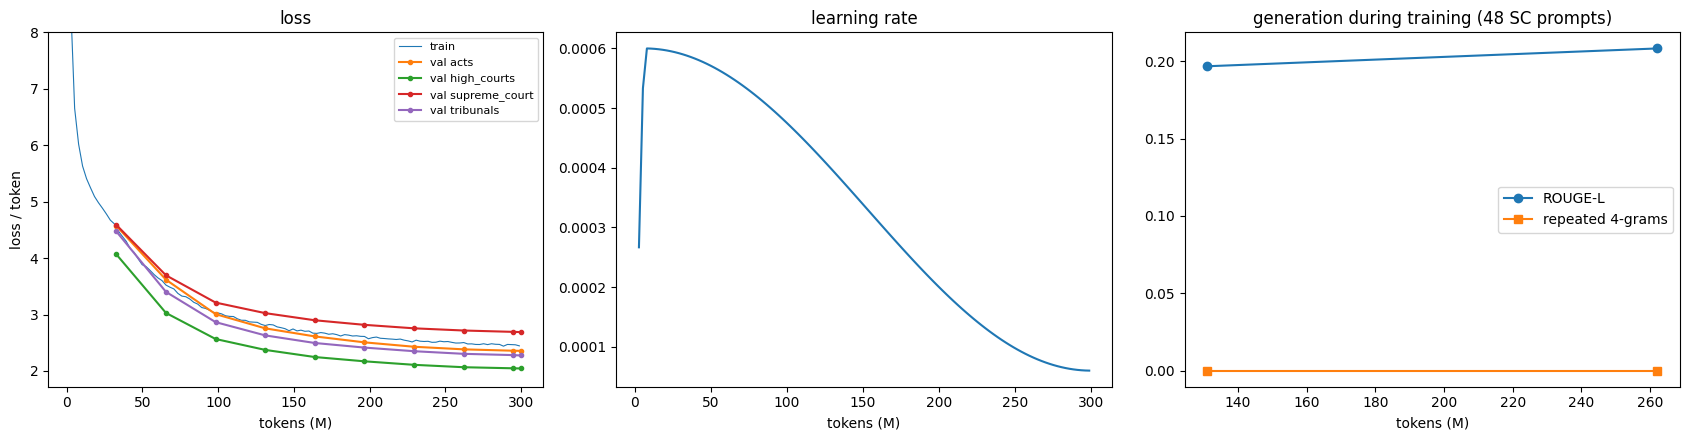

final val loss/token: {'acts': 2.3567, 'high_courts': 2.0447, 'supreme_court': 2.6889, 'tribunals': 2.2745}
final val loss/word : {'acts': 2.9087, 'high_courts': 2.6282, 'supreme_court': 3.241, 'tribunals': 3.3521}
mean throughput: 33.1k tok/s


In [11]:
import matplotlib.pyplot as plt
recs = [json.loads(l) for l in open(RUN_DIR / "metrics.jsonl")] if (RUN_DIR / "metrics.jsonl").exists() else []
tr = [r for r in recs if "loss" in r]; va = [r for r in recs if any(k.startswith("val_") for k in r)]
gn = [r for r in recs if "gen_rougeL" in r]
if tr:
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    ax[0].plot([r["tokens"] / 1e6 for r in tr], [r["loss"] for r in tr], lw=0.8, label="train")
    for src in SOURCE_NAMES:
        pts = [(r["tokens"] / 1e6, r[f"val_{src}"]) for r in va if f"val_{src}" in r]
        if pts: ax[0].plot(*zip(*pts), marker="o", ms=3, label=f"val {src}")
    ax[0].set_xlabel("tokens (M)"); ax[0].set_ylabel("loss / token"); ax[0].set_ylim(top=min(8, max(r["loss"] for r in tr)))
    ax[0].legend(fontsize=8); ax[0].set_title("loss")
    ax[1].plot([r["tokens"] / 1e6 for r in tr], [r["lr"] for r in tr]); ax[1].set_title("learning rate"); ax[1].set_xlabel("tokens (M)")
    if gn:
        ax[2].plot([r["tokens"] / 1e6 for r in gn], [r["gen_rougeL"] for r in gn], marker="o", label="ROUGE-L")
        ax[2].plot([r["tokens"] / 1e6 for r in gn], [r["gen_rep4"] for r in gn], marker="s", label="repeated 4-grams")
        ax[2].legend(); ax[2].set_title("generation during training (48 SC prompts)"); ax[2].set_xlabel("tokens (M)")
    plt.tight_layout(); plt.savefig(RUN_DIR / "curves.png", dpi=130); plt.show()
    if va:
        last = va[-1]
        print("final val loss/token:", {k[4:]: round(v, 4) for k, v in last.items() if k.startswith("val_")})
        print("final val loss/word :", {k[8:]: round(v, 4) for k, v in last.items() if k.startswith("valword_")})
    print(f"mean throughput: {np.mean([r['tok_s'] for r in tr[len(tr)//10:]])/1e3:.1f}k tok/s")

## 8. Decoding sweep on the local Supreme-Court set → choose → generate the official test set → `submission.zip`
Each decoding strategy generates continuations for the 400 local prompts and is scored with the official metric.
The best BERTScore wins and is used for the 1000 official test prompts. (Runs on one GPU in this process.)

In [12]:
def load_trained(weights="weights_final.pt"):
    from tokenizers import Tokenizer
    tok = Tokenizer.from_file(str(TOK_PATH))
    dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    m = build_model(CFG, tok.get_vocab_size())
    sd = torch.load(RUN_DIR / weights, map_location="cpu", weights_only=False)
    m.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in sd.items()})
    return m.to(dev).eval(), tok, dev

if TRAIN_DONE:
    model, tok, dev = load_trained()
    results = load_json(RUN_DIR / "decode_sweep.json", {})
    ids = list(EVAL_PROMPTS)[:N_EVAL_SWEEP]
    truth = {i: EVAL_TRUTH[i] for i in ids}
    for name, dcfg in DECODE_SWEEP.items():
        if name in results: continue
        t0 = time.time()
        preds = generate(model, tok, [EVAL_PROMPTS[i]["text"] for i in ids], dcfg, CFG["ctx_len"],
                         CFG["max_new_tokens"], CFG["gen_batch"], dev)
        gen_s = time.time() - t0
        sc = score_phase1(truth, {i: {"text": p} for i, p in zip(ids, preds)})
        sc.update({"rep4": repetition_rate(preds), "gen_seconds": gen_s, "decoding": dcfg})
        results[name] = sc; save_json(results, RUN_DIR / "decode_sweep.json")
        save_json({i: {"text": p} for i, p in zip(ids, preds)}, RUN_DIR / f"local_pred_{name}.json")
    base = load_json(ROOT / "eval" / "baselines.json", {})
    print(f"{'decoding':22s} {'BERTScore':>10s} {'ROUGE-L':>9s} {'BLEU-4':>8s} {'rep4':>6s} {'gen s':>6s}")
    for name, r in results.items():
        print(f"{name:22s} {r.get('bertscore_f1', float('nan')):10.4f} {r['rougeL']:9.4f} {r['bleu4']:8.4f} {r['rep4']:6.3f} {r['gen_seconds']:6.0f}")
    for k in ("random/copy_tail", "random/generic"):
        if k in base: print(f"{'baseline ' + k:22s} {base[k].get('bertscore_f1', float('nan')):10.4f} {base[k]['rougeL']:9.4f} {base[k]['bleu4']:8.4f}")
    key = "bertscore_f1" if all("bertscore_f1" in r for r in results.values()) else "rougeL"
    BEST_DECODE = max(results, key=lambda n: results[n][key])
    print("\nbest decoding:", BEST_DECODE, "(by", key + ")")
    i0 = ids[0]
    print("\nexample\nPROMPT …", EVAL_PROMPTS[i0]["text"][-300:], "\nMODEL  ", load_json(RUN_DIR / f"local_pred_{BEST_DECODE}.json")[i0]["text"],
          "\nTRUE   ", EVAL_TRUTH[i0]["text"])

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

... (5 outputs left out)

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


decoding                BERTScore   ROUGE-L   BLEU-4   rep4  gen s
greedy                     0.8078    0.1860   0.0364  0.718     86
greedy_nr4                 0.8335    0.2015   0.0591  0.000     82
greedy_rp1.15_nr4          0.8370    0.1928   0.0618  0.000     78
t0.7_p0.9_nr4              0.8354    0.2016   0.0555  0.000     85
baseline random/copy_tail     0.8421    0.1988   0.0845
baseline random/generic     0.8108    0.1686   0.0225

best decoding: greedy_rp1.15_nr4 (by bertscore_f1)

example
PROMPT … o exemption has been granted except to hospitals or charities. It is next urged that the imposition of a higher rate of tax for cemented, tarred, asphalted, metalled, gravel and kankar roads than that for other roads discriminates between operator, This argument overlooks the very object and purpose 
MODEL   of the Act. The argument is that the State Legislature has no power to make a law imposing tax on passengers and goods, and that it is not open to the State Legislature to ena

In [13]:
def validate_prediction(pred, test_ids, test_texts):
    assert set(pred) == set(test_ids), f"ID mismatch: missing {len(set(test_ids)-set(pred))}, extra {len(set(pred)-set(test_ids))}"
    for i in test_ids:
        t = pred[i]["text"]
        assert isinstance(t, str) and t.strip(), f"empty prediction for {i}"
        assert len(t.split()) <= CONT_WORDS, f"too long: {i}"
        assert not t.startswith(" ".join(test_texts[i].split()[:20])), f"prediction repeats prompt: {i}"
    wc = [len(pred[i]["text"].split()) for i in test_ids]
    print(f"valid: {len(pred)} predictions, words min {min(wc)} mean {np.mean(wc):.1f} max {max(wc)}")

if TRAIN_DONE:
    import zipfile
    files = load_json(find_artifact("data/files.json"))
    test = load_json(get_raw_file(files["test"], os.environ.get("CS781_LOCAL_RAW")))
    test_ids = list(test.keys()); test_texts = {i: extract_text(test[i]) for i in test_ids}
    t0 = time.time()
    preds = generate(model, tok, [test_texts[i] for i in test_ids], DECODE_SWEEP[BEST_DECODE], CFG["ctx_len"],
                     CFG["max_new_tokens"], CFG["gen_batch"], dev)
    pred = {i: {"text": p} for i, p in zip(test_ids, preds)}
    validate_prediction(pred, test_ids, test_texts)
    sub_dir = RUN_DIR / f"submission_{BEST_DECODE}"; sub_dir.mkdir(exist_ok=True)
    with open(sub_dir / "prediction.json", "w", encoding="utf-8") as f:
        json.dump(pred, f, ensure_ascii=False, indent=1)
    with zipfile.ZipFile(sub_dir / "submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(sub_dir / "prediction.json", arcname="prediction.json")
    print(f"test generation {time.time()-t0:.0f}s -> {sub_dir/'submission.zip'}")
    print("zip contents:", zipfile.ZipFile(sub_dir / "submission.zip").namelist())

test.json: 0.00B [00:00, ?B/s]

valid: 1000 predictions, words min 106 mean 128.0 max 128
test generation 192s -> /kaggle/working/cs781_p1/runs/A0_gpt2_110M_mix50_300M/submission_greedy_rp1.15_nr4/submission.zip
zip contents: ['prediction.json']


## 9. Experiment log
One row per run in `experiments.csv` (fill in the Codabench score by hand after uploading), plus `summary.json` in the run folder.

In [14]:
if TRAIN_DONE:
    info = load_json(RUN_DIR / "run_info.json"); best = results[BEST_DECODE]
    last_val = va[-1] if va else {}
    row = {"run": CFG["run_name"], "arch": CFG["arch"], "params_M": round(info["n_params"] / 1e6, 1),
           "tokens_M": round(load_json(RUN_DIR / "DONE.json")["tokens_seen"] / 1e6), "ctx": CFG["ctx_len"],
           "mix": json.dumps(CFG["mix"]), "lr": CFG["lr"], "schedule": CFG["schedule"],
           "val_sc": round(last_val.get("val_supreme_court", float("nan")), 4),
           "valword_sc": round(last_val.get("valword_supreme_court", float("nan")), 4),
           "decoding": BEST_DECODE, "local_bertscore": round(best.get("bertscore_f1", float("nan")), 4),
           "local_rougeL": round(best["rougeL"], 4), "local_bleu4": round(best["bleu4"], 4),
           "train_hours": round(tr[-1]["elapsed_h"], 2) if tr else None, "codabench_bertscore": ""}
    save_json({"row": row, "decode_sweep": results, "cfg": CFG}, RUN_DIR / "summary.json")
    exp = ROOT / "experiments.csv"; new = not exp.exists()
    with open(exp, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(row));
        if new: w.writeheader()
        w.writerow(row)
    print(json.dumps(row, indent=1))
    # keep the output small: the 1.3 GB optimizer checkpoint is only needed to resume/extend training
    print("run folder size: %.2f GB" % (sum(p.stat().st_size for p in RUN_DIR.rglob('*') if p.is_file()) / 1e9))

{
 "run": "A0_gpt2_110M_mix50_300M",
 "arch": "gpt2",
 "params_M": 111.0,
 "tokens_M": 300,
 "ctx": 1024,
 "mix": "{\"supreme_court\": 0.5, \"tribunals\": 0.2, \"high_courts\": 0.2, \"acts\": 0.1}",
 "lr": 0.0006,
 "schedule": "cosine",
 "val_sc": 2.6889,
 "valword_sc": 3.241,
 "decoding": "greedy_rp1.15_nr4",
 "local_bertscore": 0.837,
 "local_rougeL": 0.1928,
 "local_bleu4": 0.0618,
 "train_hours": 2.51,
 "codabench_bertscore": ""
}
run folder size: 2.42 GB
